In [1]:
print('test')

test


In [2]:
%pip install opendatasets pandas numpy

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install legacy-cgi

Note: you may need to restart the kernel to use updated packages.


In [4]:
import opendatasets as od
od.download('https://www.kaggle.com/c/rossmann-store-sales')

Skipping, found downloaded files in ".\rossmann-store-sales" (use force=True to force download)


In [5]:
import numpy as num
import pandas as pd



In [6]:
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [7]:
import os
os.listdir('rossmann-store-sales')

['sample_submission.csv', 'store.csv', 'test.csv', 'train.csv']

In [8]:
ross_df = pd.read_csv('./rossmann-store-sales/train.csv', low_memory=False)
  

In [9]:
ross_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1
...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1
1017205,1112,2,2013-01-01,0,0,0,0,a,1
1017206,1113,2,2013-01-01,0,0,0,0,a,1
1017207,1114,2,2013-01-01,0,0,0,0,a,1


In [10]:
store_df = pd.read_csv('./rossmann-store-sales/store.csv')

In [11]:
store_df

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1113,1114,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [12]:
merged_df = ross_df.merge(store_df, how= 'left', on = 'Store')
#All rows from ross_df are kept, and store_df's columns get pulled in and matched based on 'Store'. 
#how='left' means: keep every row from ross_df (left), and attach matching columns from store_df (right) wherever the Store values match.
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [13]:
test_df = pd.read_csv('rossmann-store-sales/test.csv')
test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0
2,3,7,4,2015-09-17,1.0,1,0,0
3,4,8,4,2015-09-17,1.0,1,0,0
4,5,9,4,2015-09-17,1.0,1,0,0
...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0
41084,41085,1112,6,2015-08-01,1.0,0,0,0
41085,41086,1113,6,2015-08-01,1.0,0,0,0
41086,41087,1114,6,2015-08-01,1.0,0,0,0


In [14]:
merged_test_df = test_df.merge(store_df, how='left',on='Store')
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [15]:
round(merged_df.describe().T,2)
#This transposes the result — flips rows and columns. Instead of statistics as rows and your data columns going across,
#"Give me summary statistics for every numeric column, flip it so columns become rows, and b

,count,mean,std,min,25%,50%,75%,max
Store,1017209.0,558.43,321.91,1.0,280.0,558.0,838.0,1115.0
DayOfWeek,1017209.0,4.00,2.00,1.0,2.0,4.0,6.0,7.0
Sales,1017209.0,5773.82,3849.93,0.0,3727.0,5744.0,7856.0,41551.0
Customers,1017209.0,633.15,464.41,0.0,405.0,609.0,837.0,7388.0
Open,1017209.0,0.83,0.38,0.0,1.0,1.0,1.0,1.0
Promo,1017209.0,0.38,0.49,0.0,0.0,0.0,1.0,1.0
SchoolHoliday,1017209.0,0.18,0.38,0.0,0.0,0.0,0.0,1.0
CompetitionDistance,1014567.0,5430.09,7715.32,20.0,710.0,2330.0,6890.0,75860.0
CompetitionOpenSinceMonth,693861.0,7.22,3.21,1.0,4.0,8.0,10.0,12.0
CompetitionOpenSinceYear,693861.0,2008.69,5.99,1900.0,2006.0,2010.0,2013.0,2015.0


In [16]:
merged_df.duplicated().sum()

np.int64(0)

In [17]:
merged_df['Date'] = pd.to_datetime(merged_df.Date)
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1017204,1111,2,2013-01-01,0,0,0,0,a,1,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1017205,1112,2,2013-01-01,0,0,0,0,a,1,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1017206,1113,2,2013-01-01,0,0,0,0,a,1,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
1017207,1114,2,2013-01-01,0,0,0,0,a,1,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


In [18]:
merged_test_df['Date'] = pd.to_datetime(merged_test_df.Date)
merged_test_df


,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,4.0,2013.0,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,10.0,2014.0,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,8.0,2000.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,NaN,NaN,0,NaN,NaN,NaN


<Axes: xlabel='Sales', ylabel='Count'>

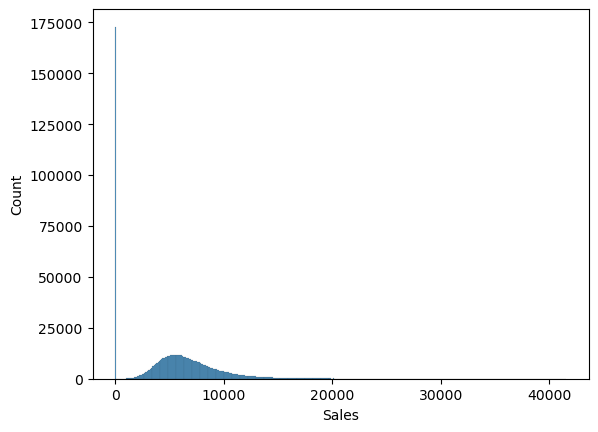

In [19]:
import plotly.express as px 
import matplotlib.pyplot as plt 
import seaborn as sns 
sns.histplot(data=merged_df, x='Sales')

In [ ]:
print(merged_df[merged_df['Sales'] == 0]['Open'].value_counts())
#meaning that sale = 0 with open = no is 172817 and open = yes is 54

Open
0    172817
1        54
Name: count, dtype: int64


In [22]:
print(pd.crosstab(merged_df['DayOfWeek'], merged_df['Open']))

Open            0       1
DayOfWeek                
1            7170  137560
2            1703  143961
3            3729  141936
4           11201  134644
5            7205  138640
6             672  144058
7          141137    3593


In [23]:
merged_df = merged_df[(merged_df['Sales'] > 0) & (merged_df['Open'] == 1)]

In [ ]:
print(pd.crosstab(merged_df['DayOfWeek'], merged_df['Open'])) #The reason that we drop the sales = 0 and open = 1 is that it is a very small number of rows (54) and it is likely that these are data entry errors.

Open            1
DayOfWeek        
1          137557
2          143955
3          141922
4          134626
5          138633
6          144052
7            3593


In [ ]:
sns.histplot(data=merged_df, x='Sales');

In [ ]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(40000)
sns.scatterplot(x=temp_df.Sales, y =temp_df.Customers, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs Customers')
plt.show()

In [ ]:
plt.figure(figsize = (18,8))
temp_df = merged_df.sample(10000)
sns.scatterplot(x=temp_df.Store, y =temp_df.Sales, hue = temp_df.Date.dt.year, alpha = 0.8)
plt.title = ('Sales Vs Store')
plt.show()

In [ ]:
merged_df.corr(numeric_only=True)['Sales'].sort_values(ascending=False)
#how to read the results: the correlation coefficient is a number between -1 and 1. A positive correlation means that as one variable increases, the other variable tends to increase as well. A negative correlation means that as one variable increases, the other variable tends to decrease. A correlation of 0 means there is no linear relationship between the two variables.

Sales                        1.000000
Customers                    0.823552
Promo                        0.368199
Promo2SinceWeek              0.095212
SchoolHoliday                0.038635
CompetitionOpenSinceYear     0.016102
Store                        0.007723
Promo2SinceYear             -0.034595
CompetitionDistance         -0.036453
CompetitionOpenSinceMonth   -0.043472
Promo2                      -0.127556
DayOfWeek                   -0.178753
Open                              NaN
Name: Sales, dtype: float64

In [32]:
#now we create a new feature from the existing one (Feature enginnering)
merged_df['Day'] = merged_df.Date.dt.day 
merged_df['Month'] = merged_df.Date.dt.month
merged_df['Year'] = merged_df.Date.dt.year

C:\Users\User\AppData\Local\Temp\ipykernel_12468\3909777492.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged_df['Day'] = merged_df.Date.dt.day
C:\Users\User\AppData\Local\Temp\ipykernel_12468\3909777492.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged_df['Month'] = merged_df.Date.dt.month
C:\Users\User\AppData\Local\Temp\ipykernel_12468\3909777492.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = va

In [33]:
merged_test_df['Day'] = merged_test_df.Date.dt.day
merged_test_df['Month'] = merged_test_df.Date.dt.month
merged_test_df['Year'] = merged_test_df.Date.dt.year

<Axes: xlabel='Year', ylabel='Sales'>

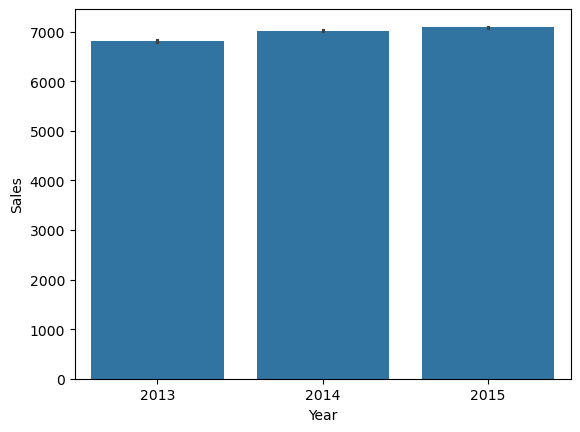

In [34]:
sns.barplot(merged_df, y= 'Sales', x = 'Year')

In [39]:
merged_df = merged_df[(merged_df['Sales'] > 0) & (merged_df['Open'] == 1)].copy()

<Axes: xlabel='Month', ylabel='Sales'>

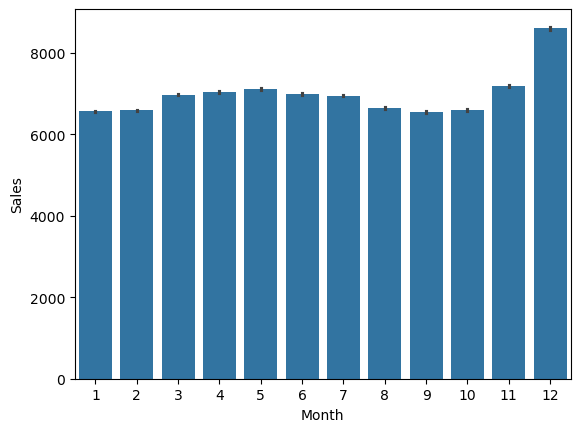

In [40]:
sns.barplot(data=merged_df, x='Month', y='Sales')

In [41]:
%pip install holidays

Note: you may need to restart the kernel to use updated packages.


In [42]:
import holidays
#Get all German public holidays for each year present in the dataset
# #use unique year in that
merged_df['Date']= pd.to_datetime(merged_df['Date'])
public_holiday = holidays.Germany(years=merged_df['Year'].unique())
#now time to create a new column with public holiday or not
merged_df['is_Public_holiday'] = merged_df['Date'].dt.date.isin(public_holiday)
#dt.date converts a Timestamp (datetime) into a Python datetime.date
merged_test_df['Date']= pd.to_datetime(merged_test_df['Date'])
merged_test_df['is_Public_holiday'] = merged_test_df['Date'].dt.date.isin(holidays.Germany(years=merged_test_df['Year'].unique()))


In [45]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,is_Public_holiday
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,9.0,2008.0,0,NaN,NaN,NaN,31,7,2015,False
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct",31,7,2015,False
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",31,7,2015,False
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,9.0,2009.0,0,NaN,NaN,NaN,31,7,2015,False
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,4.0,2015.0,0,NaN,NaN,NaN,31,7,2015,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,9.0,2006.0,0,NaN,NaN,NaN,1,1,2013,True
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,10.0,1999.0,0,NaN,NaN,NaN,1,1,2013,True
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,NaN,NaN,1,48.0,2012.0,"Jan,Apr,Jul,Oct",1,1,2013,True
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,NaN,NaN,0,NaN,NaN,NaN,1,1,2013,True


In [47]:
merged_test_df

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Day,Month,Year,is_Public_holiday
0,1,1,4,2015-09-17,1.0,1,0,0,c,a,...,9.0,2008.0,0,NaN,NaN,NaN,17,9,2015,False
1,2,3,4,2015-09-17,1.0,1,0,0,a,a,...,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct",17,9,2015,False
2,3,7,4,2015-09-17,1.0,1,0,0,a,c,...,4.0,2013.0,0,NaN,NaN,NaN,17,9,2015,False
3,4,8,4,2015-09-17,1.0,1,0,0,a,a,...,10.0,2014.0,0,NaN,NaN,NaN,17,9,2015,False
4,5,9,4,2015-09-17,1.0,1,0,0,a,c,...,8.0,2000.0,0,NaN,NaN,NaN,17,9,2015,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,41084,1111,6,2015-08-01,1.0,0,0,0,a,a,...,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct",1,8,2015,False
41084,41085,1112,6,2015-08-01,1.0,0,0,0,c,c,...,4.0,2006.0,0,NaN,NaN,NaN,1,8,2015,False
41085,41086,1113,6,2015-08-01,1.0,0,0,0,a,c,...,NaN,NaN,0,NaN,NaN,NaN,1,8,2015,False
41086,41087,1114,6,2015-08-01,1.0,0,0,0,a,c,...,NaN,NaN,0,NaN,NaN,NaN,1,8,2015,False


In [48]:
merged_test_df['is_Public_holiday'].value_counts()

is_Public_holiday
False    41088
Name: count, dtype: int64

In [49]:
merged_df['is_Public_holiday'].value_counts()

is_Public_holiday
False    843739
True        599
Name: count, dtype: int64

In [50]:
merged_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday'],
      dtype='object')

In [51]:
#The features Promo2, Promo2SinceWeek etc. are not very useful in their current form, because they do not relate to the current date. How can you improve their representation?
#Summary to find if promo2 still active until that specific date 
#Solution: 
#1. check if promo2 is available or not
#2. check if promoInterval is corrected or not(if that day(Date column) are not in range of PromoInterval , it means no promo2 actived on that date)
#3. check if Promo2SinceYear is corrected or not (if it is null or it is later that that day(date column) , it means false)
#4. same as #3 but check more if Promo2SinceYear and Date Column are in the same date but weeks-th of Date Column is smaller than PromoSinceYear's , there is no way it could happen, so false
#If they can cross all those, it mean is_activePromo is 1 


#we map from 1 : 3chars
month_map = {
   1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
#add one more column in dataset. that column is 3 chars Month
merged_df['MonthStr'] = merged_df['Date'].dt.month.map(month_map)
merged_test_df['MonthStr'] = merged_test_df['Date'].dt.month.map(month_map)

def is_promo2_active(row) : 
  if(row['Promo2']) ==0: 
    return 0
  if pd.isna(row['PromoInterval']):
    return 0
  active_months = row['PromoInterval'].split(',')
  if row['MonthStr'] not in active_months:
    return 0
  row_year, row_week, _ = row['Date'].isocalendar()
  if pd.isna(row['Promo2SinceYear']):
    return 0
  if row_year < row['Promo2SinceYear']:
    return 0
  if row_year == row['Promo2SinceYear'] and row_week <row['Promo2SinceWeek']:
    return 0
  
  return 1
# Apply the is_promo2_active() function to EVERY row in merged_df (axis=1 means "row-wise"),
# and store the resulting 0/1 values in a new column called 'IsPromo2Active'
merged_df['IsPromo2Active'] = merged_df.apply(is_promo2_active,axis = 1)
merged_test_df['IsPromo2Active'] = merged_test_df.apply(is_promo2_active,axis = 1)


In [52]:
import numpy as np
def competition_open_months(row):
  if pd.isna(row['CompetitionOpenSinceYear']) or pd.isna(row['CompetitionOpenSinceMonth']):
    return np.nan
  months  = (row['Year'] - row['CompetitionOpenSinceYear']) * 12 + ((row['Month'] - row['CompetitionOpenSinceMonth']))
  return max(months, 0)

merged_df['Num_Month_CompetitionOpen'] = merged_df.apply(competition_open_months,axis= 1)
merged_test_df['Num_Month_CompetitionOpen'] = merged_test_df.apply(competition_open_months,axis= 1)

In [53]:
merged_df['HasCompetition'] = merged_df['Num_Month_CompetitionOpen'].notna().astype(int)
merged_test_df['HasCompetition'] = merged_test_df['Num_Month_CompetitionOpen'].notna().astype(int)


In [ ]:
#make it very far (no, just to make it very far away)
merged_df['Up_CompetitionDistance'] = merged_df['CompetitionDistance'].fillna(merged_df['CompetitionDistance'].max() * 3)
merged_test_df['Up_CompetitionDistance'] = merged_test_df['CompetitionDistance'].fillna(merged_df['CompetitionDistance'].max() * 3)
#just to make it very far away

In [55]:
merged_df['CompetitionDistanceBucket'] = pd.cut(
  merged_df['Up_CompetitionDistance'],
  bins = [0, 1000, 5000, 20000, np.inf],
  labels = ['very_close', 'close', 'moderate', 'far']
)
merged_test_df['CompetitionDistanceBucket'] = pd.cut(
  merged_test_df['Up_CompetitionDistance'],
  bins = [0, 1000, 5000, 20000, np.inf],
  labels = ['very_close', 'close', 'moderate', 'far']
)

In [56]:
merged_df

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Day,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket
0,1,5,2015-07-31,5263,555,1,1,0,1,c,...,31,7,2015,False,Jul,0,82.0,1,1270.0,close
1,2,5,2015-07-31,6064,625,1,1,0,1,a,...,31,7,2015,False,Jul,1,92.0,1,570.0,very_close
2,3,5,2015-07-31,8314,821,1,1,0,1,a,...,31,7,2015,False,Jul,1,103.0,1,14130.0,moderate
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,...,31,7,2015,False,Jul,0,70.0,1,620.0,very_close
4,5,5,2015-07-31,4822,559,1,1,0,1,a,...,31,7,2015,False,Jul,0,3.0,1,29910.0,far
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1016776,682,2,2013-01-01,3375,566,1,0,a,1,b,...,1,1,2013,True,Jan,0,76.0,1,150.0,very_close
1016827,733,2,2013-01-01,10765,2377,1,0,a,1,b,...,1,1,2013,True,Jan,0,159.0,1,860.0,very_close
1016863,769,2,2013-01-01,5035,1248,1,0,a,1,b,...,1,1,2013,True,Jan,1,NaN,0,840.0,very_close
1017042,948,2,2013-01-01,4491,1039,1,0,a,1,b,...,1,1,2013,True,Jan,0,NaN,0,1430.0,close


In [58]:
merged_df[['CompetitionOpenSinceYear', 'Num_Month_CompetitionOpen', 'HasCompetition', 'CompetitionDistance', 'Up_CompetitionDistance', 'CompetitionDistanceBucket']]

,CompetitionOpenSinceYear,Num_Month_CompetitionOpen,HasCompetition,CompetitionDistance,Up_CompetitionDistance,CompetitionDistanceBucket
0,2008.0,82.0,1,1270.0,1270.0,close
1,2007.0,92.0,1,570.0,570.0,very_close
2,2006.0,103.0,1,14130.0,14130.0,moderate
3,2009.0,70.0,1,620.0,620.0,very_close
4,2015.0,3.0,1,29910.0,29910.0,far
...,...,...,...,...,...,...
1016776,2006.0,76.0,1,150.0,150.0,very_close
1016827,1999.0,159.0,1,860.0,860.0,very_close
1016863,NaN,NaN,0,840.0,840.0,very_close
1017042,NaN,NaN,0,1430.0,1430.0,close


In [60]:
# test_cutoff = the max(2015-07-31 00:00:00) minus 6 weeks , meaning the result around(2015-06-16 00:00:00)
#test_cutoff = merged_df['Date'].max() - pd.Timedelta(weeks = 6)
# test_df is only date that is bigger than 2015-06-16 00:00:00 
#test_df = merged_df[merged_df['Date'] > test_cutoff]
#train and val _df is only date that is smaller than 2015-06-16 00:00:00 
sort_df = merged_df.sort_values('Date')
train_size = int(.75 * len(sort_df))
train_df, val_df = sort_df[:train_size] , sort_df[train_size:]

In [61]:
print(test_df.shape)
print(train_df.shape)
print(val_df.shape)

(41088, 8)
(633253, 28)
(211085, 28)


In [64]:
train_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket'],
      dtype='object')

In [65]:
input_cols = merged_df.drop(columns=['Sales', 'Customers']).columns.tolist()
target_col = ['Sales']

In [66]:
train_inputs = train_df[input_cols].copy()
train_target = train_df[target_col].copy()

In [67]:
val_inputs = val_df[input_cols].copy()
val_targets = val_df[target_col].copy()

In [68]:
test_inputs = merged_test_df[input_cols].copy()

In [69]:
train_inputs

,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Day,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket
1017190,1097,2,2013-01-01,1,0,a,1,b,b,720.0,...,1,1,2013,True,Jan,0,130.0,1,720.0,very_close
1016179,85,2,2013-01-01,1,0,a,1,b,a,1870.0,...,1,1,2013,True,Jan,0,15.0,1,1870.0,close
1016353,259,2,2013-01-01,1,0,a,1,b,b,210.0,...,1,1,2013,True,Jan,0,NaN,0,210.0,very_close
1016356,262,2,2013-01-01,1,0,a,1,b,a,1180.0,...,1,1,2013,True,Jan,0,0.0,1,1180.0,close
1016368,274,2,2013-01-01,1,0,a,1,b,b,3640.0,...,1,1,2013,True,Jan,0,NaN,0,3640.0,close
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255387,369,4,2014-12-11,1,0,0,0,d,c,5870.0,...,11,12,2014,False,Dec,0,8.0,1,5870.0,moderate
255388,370,4,2014-12-11,1,0,0,0,d,a,8250.0,...,11,12,2014,False,Dec,0,170.0,1,8250.0,moderate
255389,371,4,2014-12-11,1,0,0,0,d,c,1970.0,...,11,12,2014,False,Dec,0,65.0,1,1970.0,close
255396,378,4,2014-12-11,1,0,0,0,a,c,2140.0,...,11,12,2014,False,Dec,0,28.0,1,2140.0,close


In [70]:
train_df.columns

Index(['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'PromoInterval', 'Day', 'Month', 'Year',
       'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket'],
      dtype='object')

In [71]:
train_inputs.columns

Index(['Store', 'DayOfWeek', 'Date', 'Open', 'Promo', 'StateHoliday',
       'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance',
       'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2',
       'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval', 'Day', 'Month',
       'Year', 'is_Public_holiday', 'MonthStr', 'IsPromo2Active',
       'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance',
       'CompetitionDistanceBucket'],
      dtype='object')

In [72]:
train_inputs

,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Day,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket
1017190,1097,2,2013-01-01,1,0,a,1,b,b,720.0,...,1,1,2013,True,Jan,0,130.0,1,720.0,very_close
1016179,85,2,2013-01-01,1,0,a,1,b,a,1870.0,...,1,1,2013,True,Jan,0,15.0,1,1870.0,close
1016353,259,2,2013-01-01,1,0,a,1,b,b,210.0,...,1,1,2013,True,Jan,0,NaN,0,210.0,very_close
1016356,262,2,2013-01-01,1,0,a,1,b,a,1180.0,...,1,1,2013,True,Jan,0,0.0,1,1180.0,close
1016368,274,2,2013-01-01,1,0,a,1,b,b,3640.0,...,1,1,2013,True,Jan,0,NaN,0,3640.0,close
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255387,369,4,2014-12-11,1,0,0,0,d,c,5870.0,...,11,12,2014,False,Dec,0,8.0,1,5870.0,moderate
255388,370,4,2014-12-11,1,0,0,0,d,a,8250.0,...,11,12,2014,False,Dec,0,170.0,1,8250.0,moderate
255389,371,4,2014-12-11,1,0,0,0,d,c,1970.0,...,11,12,2014,False,Dec,0,65.0,1,1970.0,close
255396,378,4,2014-12-11,1,0,0,0,a,c,2140.0,...,11,12,2014,False,Dec,0,28.0,1,2140.0,close


In [73]:
test_inputs

,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Day,Month,Year,is_Public_holiday,MonthStr,IsPromo2Active,Num_Month_CompetitionOpen,HasCompetition,Up_CompetitionDistance,CompetitionDistanceBucket
0,1,4,2015-09-17,1.0,1,0,0,c,a,1270.0,...,17,9,2015,False,Sep,0,84.0,1,1270.0,close
1,3,4,2015-09-17,1.0,1,0,0,a,a,14130.0,...,17,9,2015,False,Sep,0,105.0,1,14130.0,moderate
2,7,4,2015-09-17,1.0,1,0,0,a,c,24000.0,...,17,9,2015,False,Sep,0,29.0,1,24000.0,far
3,8,4,2015-09-17,1.0,1,0,0,a,a,7520.0,...,17,9,2015,False,Sep,0,11.0,1,7520.0,moderate
4,9,4,2015-09-17,1.0,1,0,0,a,c,2030.0,...,17,9,2015,False,Sep,0,181.0,1,2030.0,close
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41083,1111,6,2015-08-01,1.0,0,0,0,a,a,1900.0,...,1,8,2015,False,Aug,0,14.0,1,1900.0,close
41084,1112,6,2015-08-01,1.0,0,0,0,c,c,1880.0,...,1,8,2015,False,Aug,0,112.0,1,1880.0,close
41085,1113,6,2015-08-01,1.0,0,0,0,a,c,9260.0,...,1,8,2015,False,Aug,0,NaN,0,9260.0,moderate
41086,1114,6,2015-08-01,1.0,0,0,0,a,c,870.0,...,1,8,2015,False,Aug,0,NaN,0,870.0,very_close


In [ ]:
#numeric_cols is to get all the numeric columns in the train_inputs dataframe, and categorical_cols is to get all the categorical columns in the train_inputs dataframe. This is useful for preprocessing steps, such as scaling numeric features or encoding categorical features before training a machine learning model.
#catorical_cols is to get all the categorical columns in the train_inputs dataframe. This is useful for preprocessing steps, such as scaling numeric features or encoding categorical features before training a machine learning model.
numeric_cols = train_inputs[input_cols].select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = train_inputs[input_cols].select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

Numeric columns: ['Store', 'DayOfWeek', 'Open', 'Promo', 'SchoolHoliday', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'IsPromo2Active', 'Num_Month_CompetitionOpen', 'HasCompetition', 'Up_CompetitionDistance']
Categorical columns: ['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'is_Public_holiday', 'MonthStr', 'CompetitionDistanceBucket']
